# Huấn luyện mô hình phân loại câu hỏi – Student FAQ Router

Notebook này thực hiện **Step 1 (Data preparation)** và **Step 2 (AI modeling)** của dự án. Mỗi mục ứng với một gạch đầu dòng trong đề của giảng viên, kết quả (bảng, biểu đồ) dùng trực tiếp cho báo cáo.

**Cách chạy:** chỉnh các tham số ở mục 0 rồi chọn *Kernel → Restart & Run All*.

**Kết quả:**
- `models/<VERSION>/model.joblib` và `metadata.json`: model và ngưỡng mà ứng dụng dùng.
- `reports/<VERSION>/`: biểu đồ và bảng cho báo cáo.

**Giai đoạn** (`config.TRA_LOI_TU_DONG`):
- `False` – **giai đoạn 1**: mô hình phân loại câu hỏi và chuyển về đúng phòng ban. Mục 2.7 (kho FAQ) được bỏ qua.
- `True` – **giai đoạn 2**: thêm trả lời tự động bằng kho FAQ; notebook chọn thêm ngưỡng tương đồng `s_min`.

**Chế độ demo:** đặt biến môi trường `FAQ_ROUTER_DEMO=1` để chạy với dữ liệu mẫu `data/sample/`. Kết quả demo chỉ để kiểm tra code, **không dùng cho báo cáo**.

## 0. Cấu hình

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore", category=UserWarning)

import config
DEMO = config.DEMO

# ====================== THAM SỐ – nhóm chỉnh ở đây ======================
VERSION = "demo" if DEMO else "v1"     # phiên bản model sẽ tạo: v1, v2, ...
PREV_VERSION = None                    # phiên bản cũ để so sánh, ví dụ "v1" khi huấn luyện v2
DATA_PATH = config.DATA_DIR / ("sample/questions_sample.csv" if DEMO else "questions.csv")
LOG_PATH = None if DEMO else config.DATA_DIR / "log_labeled.csv"   # câu hỏi từ nhật ký đã gán nhãn (Step 4)
KAPPA_PATH = config.DATA_DIR / ("sample/kappa_sample.csv" if DEMO else "kappa_check.csv")
FAQ_PATH = config.FAQ_PATH
SPLIT_DIR = config.DATA_DIR / ("sample/splits" if DEMO else "splits")   # nơi lưu id tập test đã đóng băng
REPORT_DIR = config.REPORT_ROOT / VERSION
MUC_TIEU_PRECISION = 0.90              # precision tối thiểu của câu trả lời tự động khi chọn ngưỡng
SEED = 42
# =========================================================================

REPORT_DIR.mkdir(parents=True, exist_ok=True)
GIAI_DOAN = 2 if config.TRA_LOI_TU_DONG else 1
THEO_PHONG_BAN = GIAI_DOAN == 1   # giai đoạn 1: "đúng" nghĩa là chuyển đúng phòng ban
print("Phiên bản:", VERSION, "| Giai đoạn:", GIAI_DOAN, "| Dữ liệu:", DATA_PATH, "| Demo:", DEMO)

Phiên bản: v1 | Giai đoạn: 1 | Dữ liệu: /Users/letruonguyennhi/student-faq-router/data/questions.csv | Demo: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

import training as T
from preprocess import khong_dau
from router import doc_faq

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
TEN_NHAN = {k: v[0] for k, v in config.NHAN.items()}

def luu_hinh(ten):
    plt.tight_layout()
    plt.savefig(REPORT_DIR / ten, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Step 1 – Data preparation

### 1.1. Data requirements & Data collection
`data/questions.csv` được tạo bằng `scripts/tao_du_lieu.py` từ dữ liệu gốc trong `data/raw/` (xem README, mục *Dữ liệu*):
- `web`: câu hỏi **thật** của sinh viên trên trang hỏi đáp công khai của các trường (VHU, UIT, HLU), gán nhãn theo từ khóa rồi rà lại;
- `faq`: câu hỏi trong tài liệu hỏi–đáp của UEF, PTIT, ULAW (đã diễn đạt lại); `noise`: biến thể nhiễu của các câu đó; `generated`: câu mô phỏng về DUT.

Đọc dữ liệu và kiểm tra cấu trúc: các cột bắt buộc `id, text, label, source`; nhãn phải thuộc các nhãn trong `config.NHAN`; `id` không trùng. Bảng dưới cho biết số câu theo **nguồn** và **nhãn**, dùng cho mục *Data collection* của báo cáo.


In [3]:
df_goc = T.doc_du_lieu(DATA_PATH)
if (df_goc.source == "demo").any():
    print("⚠ Dữ liệu đang chứa câu MẪU (source = demo) — KHÔNG dùng kết quả này cho báo cáo.")
print("Tổng số câu:", len(df_goc))
pd.crosstab(df_goc.label, df_goc.source, margins=True, margins_name="Tổng")

Tổng số câu: 2815


source,faq,generated,noise,web,Tổng
label,,,,,
DO_AN,0,0,0,59,59
HOC_BONG,6,20,18,157,201
HOC_PHI,7,30,21,429,487
KHAC,23,100,69,478,670
LICH_HOC,12,30,36,455,533
LICH_THI,10,50,30,231,321
QUY_CHE,16,30,48,450,544
Tổng,74,260,222,2259,2815


### 1.2. Data labeling – độ đồng thuận giữa hai người gán nhãn
- Câu trong các file Word đã có nhãn gốc, được ánh xạ sang 7 nhãn (`data/raw/bang_anh_xa_nhan.csv`).
- Ticket trên web được gán theo từ khóa (`scripts/tao_du_lieu.py`).
- Để kiểm tra chất lượng nhãn, hai thành viên gán nhãn **độc lập** 100 câu (`data/kappa_can_gan.csv` → lưu thành `data/kappa_check.csv`).
- Hệ số **Cohen's Kappa** ≥ 0.8 là đồng thuận tốt. Các câu bất đồng được thảo luận để sửa hướng dẫn gán nhãn.
- Trên các câu hai người đồng ý, so thêm với nhãn gán theo từ khóa để biết nhãn tự động đúng bao nhiêu phần trăm.


In [4]:
if Path(KAPPA_PATH).exists():
    kappa, bat_dong = T.tinh_kappa(KAPPA_PATH)
    print(f"Cohen's Kappa = {kappa:.3f}; {len(bat_dong)} câu hai người gán khác nhau:")
    display(bat_dong)
    khop = T.do_khop_nhan_tu_dong(KAPPA_PATH, df_goc)
    if khop is not None:
        print(f"Nhãn trong dữ liệu khớp với nhãn người gán: {khop[0]:.1%}. Các câu không khớp:")
        display(khop[1])
else:
    print(f"Chưa có {KAPPA_PATH}: hai thành viên gán nhãn data/kappa_can_gan.csv rồi lưu thành file này.")


Chưa có /Users/letruonguyennhi/student-faq-router/data/kappa_check.csv: hai thành viên gán nhãn data/kappa_can_gan.csv rồi lưu thành file này.


### 1.3. Data cleaning
Chuẩn hóa Unicode (NFC), bỏ khoảng trắng thừa, bỏ câu rỗng/chưa gán nhãn, bỏ câu trùng sau khi chuẩn hóa, bỏ câu quá ngắn (< 3 từ, trừ lớp KHAC). Câu **trùng nhau nhưng khác nhãn** được liệt kê để nhóm rà lại.

In [5]:
df, bang_sach, xung_dot = T.lam_sach(df_goc)
print(f"Trước làm sạch: {len(df_goc)} câu → sau làm sạch: {len(df)} câu")
display(bang_sach)
if len(xung_dot):
    print("Câu trùng nhưng khác nhãn — cần rà lại:")
    display(xung_dot)

Trước làm sạch: 2815 câu → sau làm sạch: 2777 câu


,Bước làm sạch,Số câu bị loại
0,Bỏ câu rỗng hoặc chưa gán nhãn,0
1,Bỏ câu trùng (sau chuẩn hóa),21
2,"Bỏ câu quá ngắn (< 3 từ, trừ lớp KHAC)",17


### 1.4. Phân tích khám phá dữ liệu (EDA)

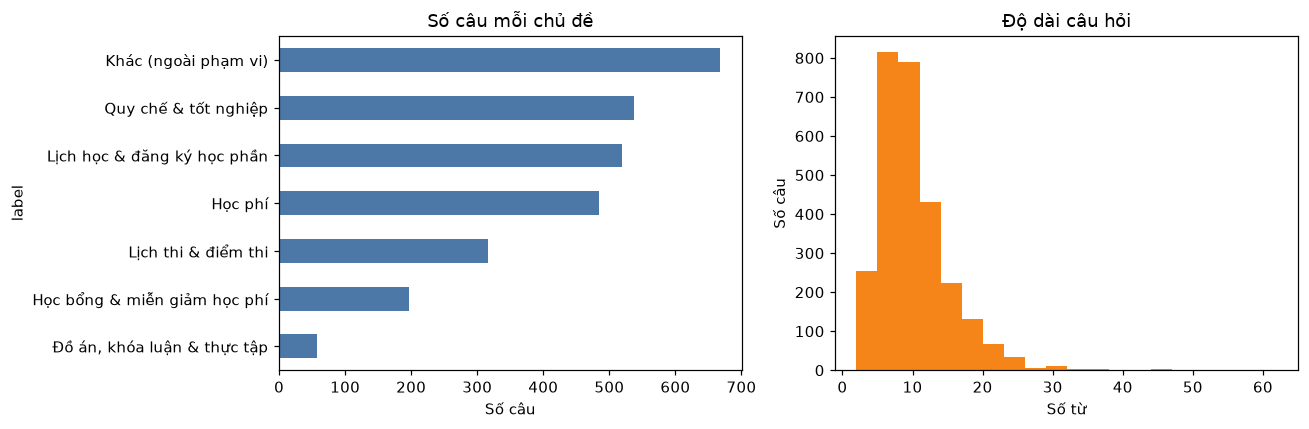

Tỉ lệ câu không dấu: 9.6%
Độ dài trung bình: 9.7 từ


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.label.map(TEN_NHAN).value_counts().sort_values().plot.barh(ax=ax[0], color="#4C78A8")
ax[0].set_title("Số câu mỗi chủ đề"); ax[0].set_xlabel("Số câu")
df.text.str.split().str.len().plot.hist(ax=ax[1], bins=20, color="#F58518")
ax[1].set_title("Độ dài câu hỏi"); ax[1].set_xlabel("Số từ"); ax[1].set_ylabel("Số câu")
luu_hinh("eda.png")
print(f"Tỉ lệ câu không dấu: {df.text.map(khong_dau).mean():.1%}")
print(f"Độ dài trung bình: {df.text.str.split().str.len().mean():.1f} từ")

### 1.5. Dataset splitting
- Tập **test** chiếm 20% số câu hỏi thật, chỉ gồm **câu hỏi thật** (nguồn trong `config.NGUON_TEST`: `form`, `facebook`, `staff`, `web`), giữ tỉ lệ các nhãn.
- Danh sách id của tập test được **đóng băng** ở `SPLIT_DIR/test_ids.txt`: các lần huấn luyện sau (v2, v3…) dùng lại đúng tập test này để so sánh công bằng.
- Câu `faq`, `noise`, `generated` và câu nhóm tự viết (`team`) chỉ nằm trong tập train.
- Nếu đã có câu hỏi từ nhật ký được gán nhãn (`LOG_PATH`, Step 4): một nửa bổ sung vào train, một nửa làm **tập test thực tế**.
- Trên tập train dùng kiểm định chéo 5-fold **theo nhóm** (`StratifiedGroupKFold`) để chọn mô hình, tham số và ngưỡng, nên không cần tập validation riêng. Các biến thể của cùng một câu gốc (cùng giá trị cột `nhom`, ví dụ 10 cách hỏi của một ý trong bộ DUT, hoặc 3 bản nhiễu của một câu FAQ) luôn nằm chung một fold, để không đánh giá trên câu gần giống câu đã học.


In [7]:
train, test, thong_bao = T.chia_tap(df, SPLIT_DIR, seed=SEED)
print(thong_bao)

test_thuc_te = None
if LOG_PATH is not None and Path(LOG_PATH).exists():
    df_log, _, _ = T.lam_sach(T.doc_du_lieu(LOG_PATH))
    log_train, test_thuc_te = T.chia_nhat_ky(df_log, SPLIT_DIR, seed=SEED)
    train = pd.concat([train, log_train], ignore_index=True)
    print(f"Nhật ký: {len(log_train)} câu bổ sung vào train, {len(test_thuc_te)} câu làm tập test thực tế.")

bang_chia = pd.DataFrame({"Train": train.label.value_counts(), "Test": test.label.value_counts()}).fillna(0).astype(int)
if test_thuc_te is not None:
    bang_chia["Test thực tế"] = test_thuc_te.label.value_counts()
bang_chia.loc["Tổng"] = bang_chia.sum()
bang_chia

Dùng lại tập test đã đóng băng (/Users/letruonguyennhi/student-faq-router/data/splits/test_ids.txt, 446 id).


,Train,Test
label,,
DO_AN,46,12
HOC_BONG,165,31
HOC_PHI,399,85
KHAC,572,95
LICH_HOC,430,89
LICH_THI,271,45
QUY_CHE,448,89
Tổng,2331,446


### 1.6. Data augmentation & Data pre-processing
- **Tiền xử lý** (`preprocess.tien_xu_ly`, dùng chung với ứng dụng): chuẩn hóa → ẩn MSSV/SĐT/email → bỏ link, dấu câu, emoji → mở rộng teencode → tách từ tiếng Việt (underthesea). **Không loại stopword** vì các từ như “khi nào”, “bao nhiêu” mang thông tin về chủ đề.
- **Tăng cường**: thêm bản **không dấu** của các câu có dấu, chỉ cho dữ liệu huấn luyện. Khi kiểm định chéo, bản không dấu chỉ được thêm vào phần train của mỗi fold, nên không bị rò rỉ sang phần đánh giá.

In [8]:
train = T.them_cot_xu_ly(train)
test = T.them_cot_xu_ly(test)
if test_thuc_te is not None:
    test_thuc_te = T.them_cot_xu_ly(test_thuc_te)
X_tmp, _ = T.tap_huan_luyen(train)
print(f"Train: {len(train)} câu gốc + {len(X_tmp) - len(train)} bản không dấu = {len(X_tmp)} câu để huấn luyện")
train[["text", "x", "x_bodau"]].head(6).rename(columns={
    "text": "Câu gốc", "x": "Sau tiền xử lý", "x_bodau": "Bản không dấu (tăng cường)"})

Train: 2331 câu gốc + 2068 bản không dấu = 4399 câu để huấn luyện


,Câu gốc,Sau tiền xử lý,Bản không dấu (tăng cường)
0,Cách đăng ký môn học như thế nào?,cách đăng_ký môn_học như_thế_nào,cach dang ky mon_hoc nhu_the nao
1,Em muốn đổi thời khóa biểu của môn mà trường đã đăng ký sẵn thì làm thế nào?,em muốn đổi thời khóa_biểu của môn mà trường đã đăng_ký sẵn thì làm thế_nào,em muon doi thoi_khoa bieu cua mon_ma truong da_dang ky san thi_lam the nao
2,Em muốn đăng ký thêm môn (học lại hoặc học vượt) ngoài các môn trường đã đăng ký sẵn thì làm thế nào?,em muốn đăng_ký thêm môn_học lại hoặc học vượt ngoài các môn_trường đã đăng_ký sẵn thì làm thế_nào,em muon dang ky them mon_hoc lai_hoac hoc vuot ngoai cac mon_truong da_dang ky san thi_lam the nao
3,"Đến ngày bắt đầu đăng ký môn học mà em không đăng ký được, có phải web bị lỗi không?",đến ngày bắt_đầu đăng_ký môn_học mà em không đăng_ký được có phải web bị lỗi không,den ngay bat dau dang ky mon_hoc ma em khong dang ky_duoc co_phai web bi_loi khong
4,Em muốn đổi sang một nhóm môn học khác nhưng nhóm đó đã đầy thì sao?,em muốn đổi sang một nhóm môn_học khác nhưng nhóm đó đã đầy thì sao,em muon doi sang mot nhom mon_hoc khac nhung nhom do da day thi sao
5,Em muốn đăng ký môn A nhưng tất cả các nhóm của môn này đã đầy thì làm thế nào?,em muốn đăng_ký môn_a nhưng tất_cả các nhóm của môn này đã đầy thì làm thế_nào,em muon dang ky mon_a nhung tat ca cac nhom cua mon nay da day thi_lam the nao


## 2. Step 2 – AI modeling

### 2.1. Model selection
So sánh 3 mô hình trên cùng đặc trưng TF-IDF (tham số mặc định), bằng kiểm định chéo 5-fold, thước đo chính **Macro-F1** (mỗi chủ đề quan trọng như nhau):
- **Naive Bayes** – mô hình cơ sở cho phân loại văn bản;
- **Logistic Regression** – mô hình tuyến tính cho ra xác suất của từng chủ đề;
- **Linear SVM** – tìm siêu phẳng phân tách các chủ đề với lề rộng nhất (soft margin, tham số C), đa lớp theo kiểu one-vs-rest.

Quy tắc chọn: mô hình có **Macro-F1 (CV) cao nhất**. Linear SVM không cho xác suất trực tiếp nên mô hình cuối được bọc `CalibratedClassifierCV` (hiệu chỉnh Platt, 3-fold) để có độ tin cậy dùng cho ngưỡng τ ở mục 2.4.

,Mô hình,Macro-F1 (CV),Độ lệch chuẩn,Accuracy (CV),Macro-F1 câu không dấu,Thời gian huấn luyện (giây/fold)
0,Naive Bayes,0.647,0.014,0.791,0.653,0.047
1,Logistic Regression,0.880,0.016,0.872,0.850,0.296
2,Linear SVM,0.897,0.021,0.897,0.876,0.059


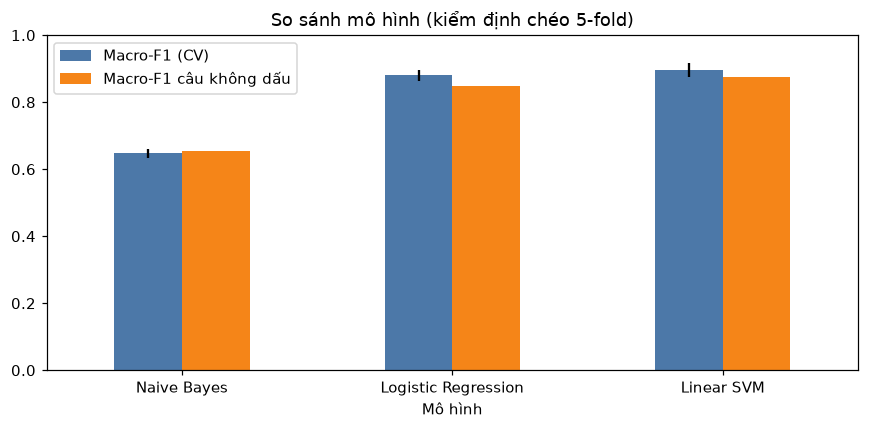

Mô hình được chọn: Linear SVM — Linear SVM có Macro-F1 (CV) cao nhất (0.897), hơn Logistic Regression 0.017.


In [9]:
so_sanh = T.so_sanh_mo_hinh(train, seed=SEED)
so_sanh.round(3).to_csv(REPORT_DIR / "so_sanh_mo_hinh.csv", index=False)
display(so_sanh.round(3))

ax = so_sanh.set_index("Mô hình")[["Macro-F1 (CV)", "Macro-F1 câu không dấu"]].plot.bar(
    rot=0, figsize=(8, 4), color=["#4C78A8", "#F58518"], yerr={"Macro-F1 (CV)": so_sanh["Độ lệch chuẩn"].values})
ax.set_ylim(0, 1); ax.set_title("So sánh mô hình (kiểm định chéo 5-fold)")
luu_hinh("so_sanh_mo_hinh.png")

TEN_MO_HINH, LY_DO = T.chon_mo_hinh(so_sanh)
print("Mô hình được chọn:", TEN_MO_HINH, "—", LY_DO)

### 2.2. Thí nghiệm nhỏ (ablation)
Mỗi lần bỏ một yếu tố của bước tiền xử lý để xem yếu tố đó đóng góp bao nhiêu. Cột *câu không dấu* cho biết mô hình có chịu được cách gõ không dấu của sinh viên hay không.

In [10]:
ablation = T.thi_nghiem_nho(train, TEN_MO_HINH)
ablation.round(3).to_csv(REPORT_DIR / "thi_nghiem_nho.csv", index=False)
ablation.round(3)

,Cấu hình,Macro-F1 (CV),Macro-F1 câu không dấu
0,Đầy đủ (tách từ + tăng cường không dấu),0.897,0.876
1,Không tách từ,0.929,0.922
2,Không tăng cường không dấu,0.890,0.604


### 2.3. Model tuning
Tìm kiếm lưới (grid search) với kiểm định chéo 5-fold trên: tham số điều chuẩn của mô hình (`C` hoặc `alpha`), đặc trưng theo **từ** (n-gram 1–2) hay theo **ký tự** (n-gram 2–5), `min_df`, `sublinear_tf`.

In [11]:
THAM_SO, luoi = T.tim_tham_so(train, TEN_MO_HINH, seed=SEED)
luoi.to_csv(REPORT_DIR / "tim_tham_so.csv", index=False)
print(f"Đã thử {len(luoi)} tổ hợp. Tham số tốt nhất (Macro-F1 CV = {luoi.loc[0, 'Macro-F1 (CV)']:.3f}):")
print(THAM_SO)
luoi.head(10).round(3)

Đã thử 64 tổ hợp. Tham số tốt nhất (Macro-F1 CV = 0.924):
{'tfidf__analyzer': 'char_wb', 'tfidf__ngram_range': (2, 5), 'tfidf__min_df': 1, 'tfidf__sublinear_tf': True, 'clf__C': 1.0}


,clf__C,tfidf__analyzer,tfidf__min_df,tfidf__ngram_range,tfidf__sublinear_tf,Macro-F1 (CV),Độ lệch chuẩn
0,1.0,char_wb,1,"(2, 5)",True,0.924,0.011
1,1.0,char_wb,1,"(2, 5)",False,0.924,0.014
2,1.0,char_wb,2,"(2, 5)",False,0.924,0.013
3,1.0,char_wb,2,"(2, 5)",True,0.924,0.011
4,1.0,char_wb,2,"(2, 4)",True,0.922,0.012
5,1.0,char_wb,1,"(2, 4)",True,0.922,0.012
6,10.0,char_wb,1,"(2, 5)",True,0.921,0.020
7,10.0,char_wb,2,"(2, 5)",True,0.921,0.019
8,1.0,char_wb,1,"(2, 4)",False,0.919,0.018
9,10.0,char_wb,1,"(2, 5)",False,0.918,0.021


**Thí nghiệm nhỏ với tham số tốt nhất:** lặp lại mục 2.2 với cấu hình vừa chọn, để quyết định giữ hay bỏ từng bước tiền xử lý dựa trên đúng cấu hình sẽ dùng (kết quả ở mục 2.2 dùng tham số mặc định, có thể khác).

In [12]:
ablation_cuoi = T.thi_nghiem_nho(train, TEN_MO_HINH, THAM_SO)
ablation_cuoi.round(3).to_csv(REPORT_DIR / "thi_nghiem_nho_sau_tinh_chinh.csv", index=False)
ablation_cuoi.round(3)

,Cấu hình,Macro-F1 (CV),Macro-F1 câu không dấu
0,Đầy đủ (tách từ + tăng cường không dấu),0.924,0.896
1,Không tách từ,0.919,0.885
2,Không tăng cường không dấu,0.915,0.667


### 2.4. Chọn ngưỡng tin cậy τ
Câu có độ tin cậy ≥ τ được **xử lý tự động**: ở giai đoạn 1 là chuyển thẳng đến phòng ban phụ trách, ở giai đoạn 2 là trả lời bằng kho FAQ. Câu có độ tin cậy < τ được chuyển cho **Phòng Công tác sinh viên phân loại thủ công** (đúng bước 2 của Quy trình QT_11_CTSV).

Dùng xác suất **ngoài mẫu** từ kiểm định chéo (mỗi câu được dự đoán bởi mô hình chưa thấy câu đó). Với mỗi τ: *coverage* là tỉ lệ câu được xử lý tự động, *precision* là tỉ lệ đúng trong các câu đó (giai đoạn 1 tính **theo phòng ban**). Chọn τ nhỏ nhất đạt precision ≥ `MUC_TIEU_PRECISION`.

τ = 0.20 là ngưỡng nhỏ nhất đạt precision ≥ 90%.


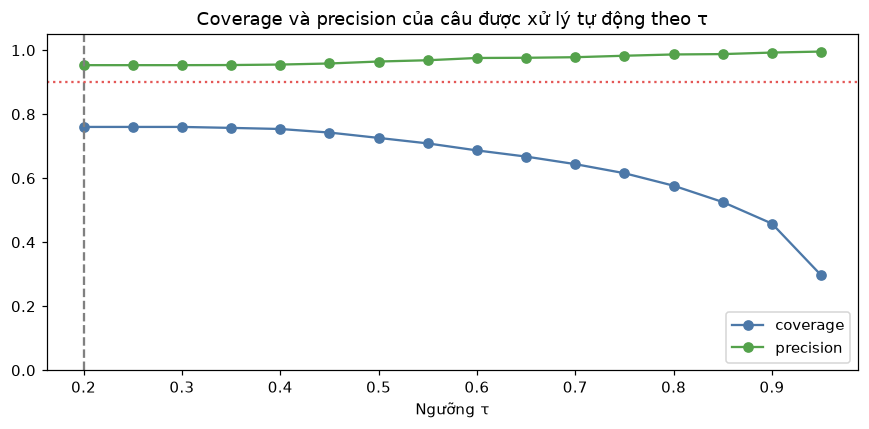

In [13]:
cv_cuoi = T.danh_gia_cheo(train, TEN_MO_HINH, THAM_SO, xac_suat=True, seed=SEED)
TAU, bang_tau, ghi_chu_tau = T.chon_nguong(cv_cuoi["oof"], cv_cuoi["lop"], train.label, MUC_TIEU_PRECISION,
                                           theo_phong_ban=THEO_PHONG_BAN)
print(ghi_chu_tau)
bang_tau.round(3).to_csv(REPORT_DIR / "chon_nguong.csv", index=False)

ax = bang_tau.plot(x="tau", y=["coverage", "precision"], marker="o", figsize=(8, 4), color=["#4C78A8", "#54A24B"])
ax.axvline(TAU, ls="--", color="grey"); ax.axhline(MUC_TIEU_PRECISION, ls=":", color="#E45756")
ax.set_ylim(0, 1.05); ax.set_xlabel("Ngưỡng τ"); ax.set_title("Coverage và precision của câu được xử lý tự động theo τ")
luu_hinh("chon_nguong.png")

### 2.5. Huấn luyện mô hình cuối cùng trên toàn bộ tập train

In [14]:
model = T.huan_luyen_cuoi(train, TEN_MO_HINH, THAM_SO)
print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                                 sublinear_tf=True)),
                ('clf',
                 CalibratedClassifierCV(cv=3,
                                        estimator=LinearSVC(class_weight='balanced')))])


### 2.6. Model evaluation – đánh giá trên tập test (một lần duy nhất)
Các chỉ số: Accuracy và Macro-F1 theo chủ đề, **Accuracy theo phòng ban**, recall lớp KHAC, tỉ lệ và precision của câu được xử lý tự động tại τ, Macro-F1 khi câu test bị bỏ dấu (độ bền), thời gian dự đoán.

In [15]:
ev = T.danh_gia_tap(model, test, TAU, "Test", theo_phong_ban=THEO_PHONG_BAN)
bang_test = [ev["chi_so"]]
if test_thuc_te is not None:
    bang_test.append(T.danh_gia_tap(model, test_thuc_te, TAU, "Test thực tế", theo_phong_ban=THEO_PHONG_BAN)["chi_so"])
bang_test = pd.DataFrame(bang_test)
THOI_GIAN_MS = T.do_thoi_gian(model, test.text)
bang_test.round(3).to_csv(REPORT_DIR / "danh_gia_test.csv", index=False)
display(bang_test.round(3))
print(f"Thời gian tiền xử lý + dự đoán trung bình: {THOI_GIAN_MS:.1f} ms/câu")
print(ev["bao_cao"])

,Tập,Số câu,Accuracy,Macro-F1,Accuracy theo phòng ban,Recall lớp KHAC,Tỉ lệ xử lý tự động,Precision xử lý tự động,Macro-F1 câu không dấu
0,Test,446,0.93,0.946,0.953,0.874,0.8,0.958,0.931


Thời gian tiền xử lý + dự đoán trung bình: 1.7 ms/câu
              precision    recall  f1-score   support

       DO_AN      1.000     1.000     1.000        12
    HOC_BONG      1.000     1.000     1.000        31
     HOC_PHI      0.964     0.953     0.959        85
        KHAC      0.933     0.874     0.902        95
    LICH_HOC      0.894     0.944     0.918        89
    LICH_THI      0.898     0.978     0.936        45
     QUY_CHE      0.920     0.899     0.909        89

    accuracy                          0.930       446
   macro avg      0.944     0.950     0.946       446
weighted avg      0.931     0.930     0.930       446



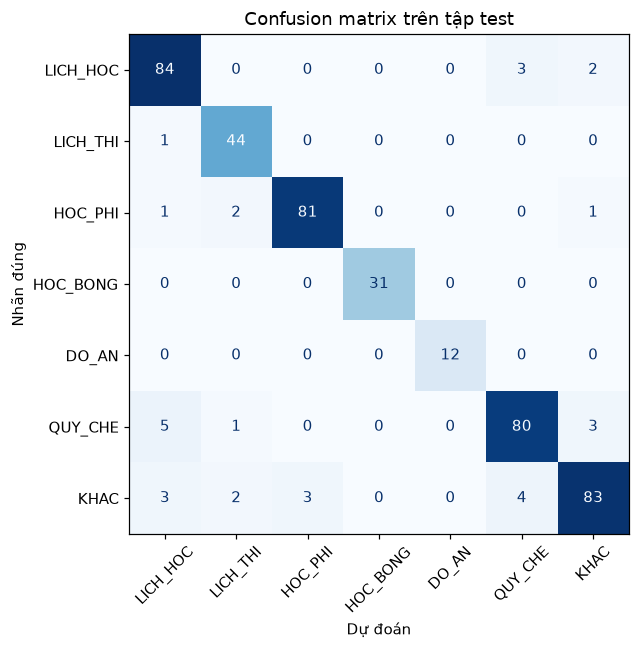

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
nhan = [n for n in config.NHAN if n in set(test.label) | set(ev["du_doan"])]
ConfusionMatrixDisplay.from_predictions(test.label, ev["du_doan"], labels=nhan, ax=ax,
                                        xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix trên tập test"); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn đúng")
luu_hinh("confusion_matrix.png")

**Kết quả chuyển phòng ban trên tập test** — mỗi hàng là phòng ban đúng, mỗi cột là nơi hệ thống chuyển câu hỏi đến. Câu có độ tin cậy < τ được tính vào cột *Phòng Công tác sinh viên (phân loại thủ công)*.

In [17]:
proba_test = model.predict_proba(test.x)
chuyen_den = np.where((proba_test.max(1) < TAU), f"{config.PHONG_BAN_XEM_LAI} (phân loại thủ công)",
                      [config.phong_ban(n) for n in ev["du_doan"]])
bang_pb = pd.crosstab(test.label.map(config.phong_ban).rename("Phòng ban đúng"),
                      pd.Series(chuyen_den, name="Hệ thống chuyển đến"), margins=True, margins_name="Tổng")
bang_pb.to_csv(REPORT_DIR / "chuyen_phong_ban.csv")
bang_pb

Hệ thống chuyển đến,Phòng Công tác sinh viên,Phòng Kế hoạch - Tài chính,Phòng Đào tạo và Bảo đảm chất lượng,Văn phòng Khoa,Tổng
Phòng ban đúng,,,,,
Phòng Công tác sinh viên,114,3,9,0,126
Phòng Kế hoạch - Tài chính,1,81,3,0,85
Phòng Đào tạo và Bảo đảm chất lượng,5,0,218,0,223
Văn phòng Khoa,0,0,0,12,12
Tổng,120,84,230,12,446


**Phân tích lỗi:** các câu dự đoán sai (lưu ở `reports/<VERSION>/loi_du_doan.csv`). Nhóm điền thêm cột nguyên nhân (câu nhiều ý, nhãn mơ hồ, từ hiếm, lỗi chính tả…) cho báo cáo.

In [18]:
ev["loi"].to_csv(REPORT_DIR / "loi_du_doan.csv", index=False)
ev["loi"].round(3)

,id,text,label,du_doan,tin_cay
2,UIT-112220,Vấn đề học Anh văn ở ngoài,KHAC,LICH_HOC,0.522
23,UIT-122333,Số tín chỉ các môn học?,QUY_CHE,LICH_HOC,0.672
28,UIT-123522,có nên đăng kí học chương trình cử nhân tài năng?,LICH_HOC,QUY_CHE,0.516
31,UIT-127445,Dành cho bạn nào cần phòng trọ ở lại học kì hè ( tháng 7 - 8 ),KHAC,LICH_HOC,0.435
36,UIT-134966,vấn đề tính cách và nghề nghiệp ?,KHAC,QUY_CHE,0.931
51,UIT-149449,18 tuổi học trung cấp nghề?,KHAC,LICH_HOC,0.725
90,VHU-16868,chuyển lớp chung với nhau,LICH_HOC,QUY_CHE,0.730
104,VHU-1783,"Thời khóa biểu, chuyển ngành",QUY_CHE,LICH_HOC,0.568
120,VHU-18253,sinh viên muốn đi học lại,QUY_CHE,LICH_HOC,0.567
127,VHU-18503,đăng ký thi B1 ngoại ngữ,KHAC,LICH_THI,0.504


**Giải thích mô hình:** các từ/cụm từ có trọng số cao nhất của mỗi chủ đề.

In [19]:
tu = T.tu_dac_trung(model, 10)
tu.to_csv(REPORT_DIR / "tu_dac_trung.csv", index=False)
tu

,DO_AN,HOC_BONG,HOC_PHI,KHAC,LICH_HOC,LICH_THI,QUY_CHE
0,luan,bong,phi,tuy,học,thi,luu
1,luan,bon,phi,tuy,ọc,thi,luu
2,tap,bon,phi,yt,học,thi,chuy
3,tap,bong,phi,yt,phan,thi,ra
4,lua,bong,phi_,bhyt,phan,hi,luu
5,thuc,bo,phi_,bhy,hoc,hi,luu
6,thuc,bo,ph,hyt,bieu,hao,chuy
7,tap,giam,hi_,bh,bieu,khao,ngh
8,tap,iam,_phí,bhyt,bieu,khao,ra
9,lu,giam,_phí,hyt,bi,i,ra


### 2.7. (Giai đoạn 2) Đánh giá bước chọn câu FAQ và ngưỡng s_min
Chỉ chạy khi `config.TRA_LOI_TU_DONG = True`. Trên các câu có ghi `faq_id` (câu FAQ đúng), hệ thống dự đoán chủ đề rồi tìm câu FAQ giống nhất trong chủ đề đó. Chọn `s_min` nhỏ nhất đạt precision ≥ `MUC_TIEU_PRECISION`; câu không đủ giống FAQ nào sẽ được chuyển đến phòng ban.

In [20]:
S_MIN = None
if GIAI_DOAN == 1:
    print("Giai đoạn 1 (chỉ phân loại và chuyển phòng ban): bỏ qua bước chọn câu FAQ.")
else:
    faq = doc_faq(FAQ_PATH)
    print(f"Kho FAQ: {len(faq)} câu")
    display(faq.label.map(TEN_NHAN).value_counts().rename("Số câu FAQ"))
    S_MIN, bang_s, ghi_chu_s = T.danh_gia_faq(model, faq, pd.concat([train, test]), MUC_TIEU_PRECISION)
    print(ghi_chu_s)
    if bang_s is None:
        S_MIN = 0.2
        print("Tạm dùng s_min = 0.2. Ghi faq_id cho khoảng 50 câu để chọn ngưỡng theo dữ liệu.")
    else:
        bang_s.round(3).to_csv(REPORT_DIR / "chon_nguong_faq.csv", index=False)
        display(bang_s.round(3))

Giai đoạn 1 (chỉ phân loại và chuyển phòng ban): bỏ qua bước chọn câu FAQ.


### 2.8. So sánh với phiên bản trước (khi huấn luyện lại – Step 4)
Đặt `PREV_VERSION = "v1"` ở mục 0 khi huấn luyện v2. Hai phiên bản được đánh giá trên **cùng** tập test gốc (đã đóng băng) và tập test thực tế. Chỉ thay model trong `config.py` nếu phiên bản mới không kém hơn.

In [21]:
if PREV_VERSION:
    import json, joblib
    thu_muc_cu = config.MODEL_ROOT / PREV_VERSION
    model_cu = joblib.load(thu_muc_cu / "model.joblib")
    tau_cu = json.loads((thu_muc_cu / "metadata.json").read_text(encoding="utf-8"))["nguong_tin_cay"]
    hang = []
    for ten_tap, tap in [("Test gốc", test), ("Test thực tế", test_thuc_te)]:
        if tap is None:
            continue
        for pb, m, t in [(PREV_VERSION, model_cu, tau_cu), (VERSION, model, TAU)]:
            chi_so = T.danh_gia_tap(m, tap, t, theo_phong_ban=THEO_PHONG_BAN)["chi_so"]
            hang.append({"Tập": ten_tap, "Phiên bản": pb, **{k: v for k, v in chi_so.items() if k != "Tập"}})
    so_sanh_pb = pd.DataFrame(hang)
    so_sanh_pb.round(3).to_csv(REPORT_DIR / "so_sanh_phien_ban.csv", index=False)
    display(so_sanh_pb.round(3))
else:
    print("PREV_VERSION = None: bỏ qua so sánh phiên bản.")

PREV_VERSION = None: bỏ qua so sánh phiên bản.


### 2.9. Lưu model và metadata

In [22]:
ct = ev["chi_so"]
thu_muc = T.luu_model(model, config.MODEL_ROOT / VERSION, {
    "phien_ban": VERSION, "giai_doan": GIAI_DOAN, "demo": DEMO, "du_lieu": str(Path(DATA_PATH).relative_to(ROOT)),
    "mo_hinh": TEN_MO_HINH, "ly_do_chon": LY_DO, "tham_so": THAM_SO,
    "nguong_tin_cay": TAU, "nguong_tuong_dong": S_MIN,
    "so_cau_train": len(train), "so_cau_test": len(test),
    "macro_f1_cv": float(luoi.loc[0, "Macro-F1 (CV)"]),
    "chi_so_test": {k: (None if pd.isna(v) else float(v)) for k, v in ct.items() if k not in ("Tập", "Số câu")},
    "thoi_gian_ms_moi_cau": THOI_GIAN_MS,
})
print("Đã lưu:", thu_muc)
print(f"Mô hình: {TEN_MO_HINH} | τ = {TAU:.2f} | s_min = {S_MIN} | Macro-F1 test = {ct['Macro-F1']:.3f} "
      f"| Accuracy theo phòng ban = {ct['Accuracy theo phòng ban']:.3f}")
if VERSION != config.MODEL_VERSION:
    print(f"Lưu ý: ứng dụng đang dùng MODEL_VERSION = {config.MODEL_VERSION!r} (config.py).")

Đã lưu: /Users/letruonguyennhi/student-faq-router/models/v1
Mô hình: Linear SVM | τ = 0.20 | s_min = None | Macro-F1 test = 0.946 | Accuracy theo phòng ban = 0.953
